# ENVIRONMENT SETUP

In [5]:
%pip install tensorflow

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.3 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [6]:
import sys
print("Python version:", sys.version)
print("Environment location:", sys.executable)

Python version: 3.14.2 (tags/v3.14.2:df79316, Dec  5 2025, 17:18:21) [MSC v.1944 64 bit (AMD64)]
Environment location: c:\Users\linam\AppData\Local\Programs\Python\Python314\python.exe


In [7]:
!pip list

Package                   Version
------------------------- -----------
absl-py                   2.4.0
anaconda-anon-usage       0.7.5
anaconda-auth             0.12.3
anaconda-cli-base         0.7.0
annotated-types           0.6.0
anyio                     4.13.0
archspec                  0.2.5
argon2-cffi               25.1.0
argon2-cffi-bindings      25.1.0
arrow                     1.4.0
asttokens                 3.0.1
astunparse                1.6.3
async-lru                 2.3.0
attrs                     26.1.0
babel                     2.18.0
beautifulsoup4            4.14.3
bleach                    6.3.0
boltons                   25.0.0
brotlicffi                1.2.0.0
certifi                   2025.11.12
cffi                      2.0.0
charset-normalizer        3.4.4
click                     8.2.1
colorama                  0.4.6
comm                      0.2.3
conda                     25.11.1
conda-anaconda-telemetry  0.3.0
conda-anaconda-tos        0.2.2
conda-content-t

In [8]:
import tensorflow as tf
from tensorflow.keras.datasets import mnist
import numpy as np
import matplotlib.pyplot as plt

In [9]:
#Load MNIST dataset
(x_train, y_train), (x_test, y_test) = mnist.load_data()

#validating the load
print("x_train shape:", x_train.shape)
print("y_train shape:", y_train.shape)
print("x_test shape:", x_test.shape)
print("y_test shape:", y_test.shape)

x_train shape: (60000, 28, 28)
y_train shape: (60000,)
x_test shape: (10000, 28, 28)
y_test shape: (10000,)


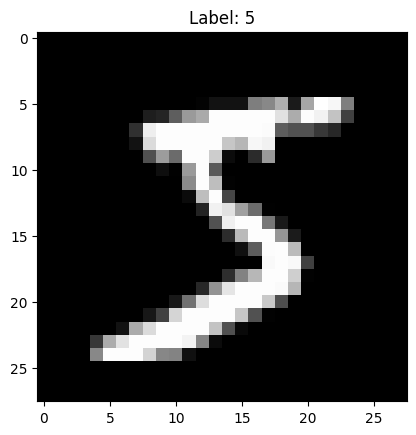

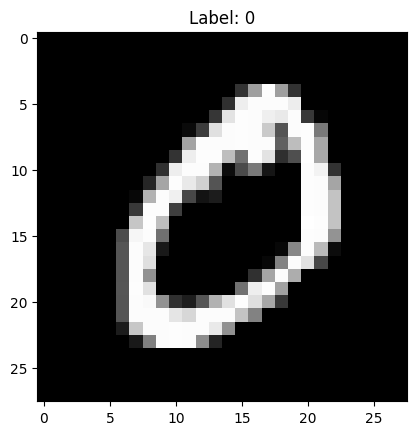

In [10]:
#exampleees
for i in range(2):
    plt.imshow(x_train[i], cmap='gray')
    plt.title(f"Label: {y_train[i]}")
    plt.show()

# feature scaling  
normalize the data: we have the range pixels ( the input) is too high from 0 to 225 

In [11]:
x_train = x_train / 255.0
x_test = x_test / 255.0 

# Reshaping the data:  from matrix 28*28 to vector 785

In [12]:
x_train = x_train.reshape(-1, 784)
x_test = x_test.reshape(-1, 784)

# Encode the labels ? 

In [13]:
from tensorflow.keras.utils import to_categorical

y_train = to_categorical(y_train, 10)
y_test = to_categorical(y_test, 10)

# 1 building the neural network 

In [14]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense

model = Sequential() #creating an empty neural network

model.add(Dense(128, activation='relu', input_shape=(784,))) #layer1 + hidden
model.add(Dense(64, activation='relu')) #hidden layer: Takes the 128 outputs from previous layer and Produces 64 new features
model.add(Dense(10, activation='softmax')) #output layer, softmax function: Converts outputs into probabilities

c:\Users\linam\AppData\Local\Programs\Python\Python314\Lib\site-packages\keras\src\layers\core\dense.py:100: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


# 2 we compile the model 
how wrong is the model, how accurate, how optimized ...

In [15]:
model.compile(
    optimizer='adam',
    loss='categorical_crossentropy',
    metrics=['accuracy', 'Precision', 'Recall']
)

# 3 train the model

In [16]:
model.fit(x_train, y_train, epochs=10, batch_size=32)

Epoch 1/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 7s 3ms/step - Precision: 0.9528 - Recall: 0.9030 - accuracy: 0.9276 - loss: 0.2481
Epoch 2/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 7s 4ms/step - Precision: 0.9749 - Recall: 0.9648 - accuracy: 0.9693 - loss: 0.1028
Epoch 3/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 7s 4ms/step - Precision: 0.9822 - Recall: 0.9765 - accuracy: 0.9789 - loss: 0.0699
Epoch 4/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 6s 3ms/step - Precision: 0.9860 - Recall: 0.9821 - accuracy: 0.9841 - loss: 0.0522
Epoch 5/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 6s 3ms/step - Precision: 0.9894 - Recall: 0.9867 - accuracy: 0.9880 - loss: 0.0388
Epoch 6/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 7s 4ms/step - Precision: 0.9908 - Recall: 0.9889 - accuracy: 0.9897 - loss: 0.0318
Epoch 7/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 8s 4ms/step - Precision: 0.9917 - Recall: 0.9903 - accuracy: 0.9909 - loss: 0.0267
Epoch 8/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 7s 4ms/step - Precision: 0.9928 - Recall: 0.9916 - accuracy: 0.9922 - loss: 0.0239


# 4 evaluation of the model 

In [17]:
results = model.evaluate(x_test, y_test)

loss = results[0]
accuracy = results[1]

print("Test loss:", loss)
print("Test accuracy:", accuracy)

313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - Precision: 0.9787 - Recall: 0.9777 - accuracy: 0.9780 - loss: 0.0976
Test loss: 0.097610242664814
Test accuracy: 0.9779999852180481


# viz learning

Epoch 1/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 7s 4ms/step - Precision: 0.9941 - Recall: 0.9934 - accuracy: 0.9938 - loss: 0.0182
Epoch 2/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 7s 4ms/step - Precision: 0.9950 - Recall: 0.9946 - accuracy: 0.9947 - loss: 0.0148
Epoch 3/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 6s 3ms/step - Precision: 0.9950 - Recall: 0.9948 - accuracy: 0.9949 - loss: 0.0145
Epoch 4/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 7s 4ms/step - Precision: 0.9952 - Recall: 0.9948 - accuracy: 0.9951 - loss: 0.0136
Epoch 5/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 7s 4ms/step - Precision: 0.9959 - Recall: 0.9955 - accuracy: 0.9958 - loss: 0.0120
Epoch 6/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 6s 3ms/step - Precision: 0.9961 - Recall: 0.9958 - accuracy: 0.9960 - loss: 0.0117
Epoch 7/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 7s 4ms/step - Precision: 0.9969 - Recall: 0.9967 - accuracy: 0.9968 - loss: 0.0097
Epoch 8/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 7s 4ms/step - Precision: 0.9960 - Recall: 0.9958 - accuracy: 0.9959 - loss: 0.0121


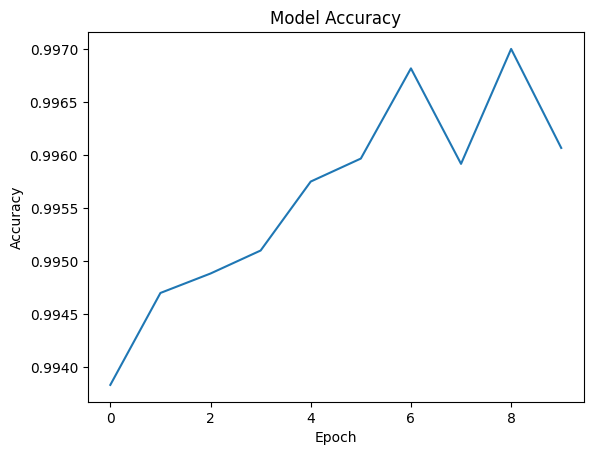

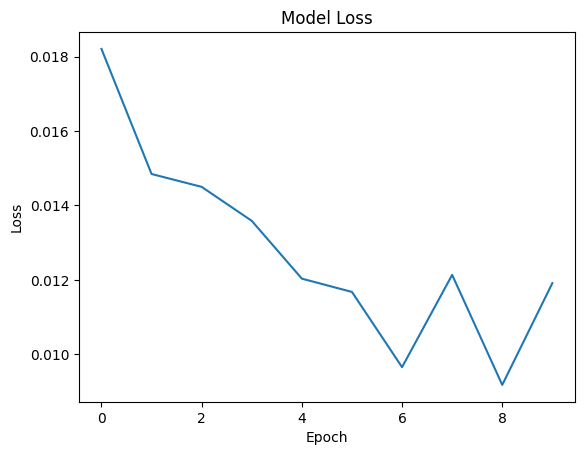

In [18]:
import matplotlib.pyplot as plt
history = model.fit(x_train, y_train, epochs=10, batch_size=32)
# Accuracy
plt.plot(history.history['accuracy'])
plt.title('Model Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.show()

# Loss
plt.plot(history.history['loss'])
plt.title('Model Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.show()

Accuracy graph: goes UP 
 Loss graph: goes DOWN 
 --> That means the model is learning

# viz predictions 

313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step


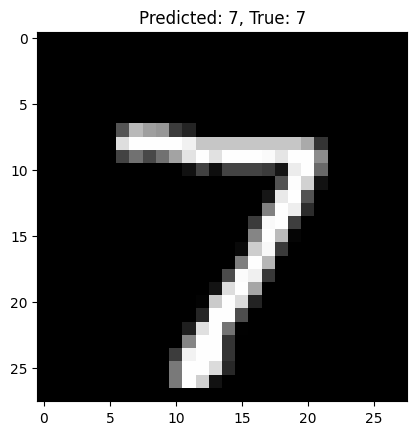

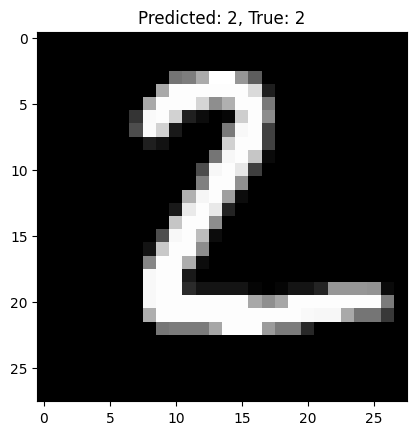

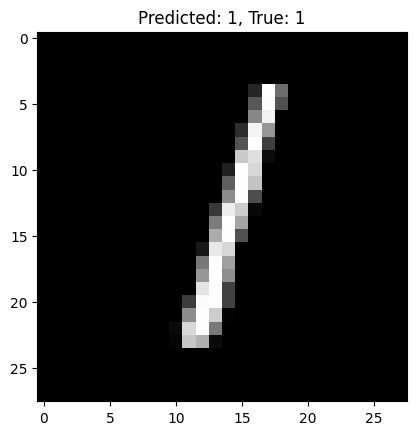

In [19]:
import numpy as np

# Predict
predictions = model.predict(x_test)
for i in range(3):
    plt.imshow(x_test[i].reshape(28,28), cmap='gray')
    
    predicted_label = np.argmax(predictions[i])
    true_label = np.argmax(y_test[i])
    
    plt.title(f"Predicted: {predicted_label}, True: {true_label}")
    plt.show()

In [20]:
model.save("mnist_model.keras")